This is the file for homework 02 on training a regression modal. The goal of this homework is to create a regression model for predicting the car fuel efficiency (column 'fuel_efficiency_mpg').

In [147]:
import pandas as pd
import numpy as np

In [148]:
df = pd.read_csv("car_fuel_efficiency_2026.csv")

In [149]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  object 
 2   fuel_type            10000 non-null  object 
 3   drivetrain           10000 non-null  object 
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           9123 non-null   float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         9736 non-null   float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), object(3)
memory usage: 859.5+ KB


In [150]:
df.dtypes

model_year               int64
origin                  object
fuel_type               object
drivetrain              object
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [151]:
df.head(5)


,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [152]:
df.describe()

,model_year,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
count,10000.000000,10000.00000,10000.000000,10000.000000,9123.000000,10000.000000,9736.000000,10000.000000
mean,1999.549500,3.50400,2268.807000,6.035200,254.446016,4286.754000,18.888044,29.997700
std,14.207925,0.95209,183.447355,0.542578,22.844613,266.212491,1.279543,2.930245
min,1975.000000,2.00000,1590.000000,4.000000,171.000000,3320.000000,14.000000,19.800000
25%,1987.000000,3.00000,2150.000000,6.000000,239.000000,4110.000000,18.000000,28.000000
50%,2000.000000,4.00000,2270.000000,6.000000,254.000000,4280.000000,18.900000,30.000000
75%,2012.000000,4.00000,2390.000000,6.000000,270.000000,4470.000000,19.700000,31.900000
max,2024.000000,5.00000,3110.000000,8.000000,334.000000,5460.000000,23.800000,41.200000


In [153]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
print(df.columns)

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='object')


Lets look at every column

In [154]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

model_year
[2006 2008 1996 1989 1994]
50

origin
['Europe' 'Asia' 'USA']
3

fuel_type
['Gasoline' 'Diesel' 'Hybrid']
3

drivetrain
['Front-wheel drive' 'Rear-wheel drive' 'All-wheel drive']
3

num_doors
[4 5 3 2]
4

engine_displacement
[2180 2390 2320 2130 2580]
127

num_cylinders
[6 7 5 8 4]
5

horsepower
[243. 272. 267. 258. 304.]
153

vehicle_weight
[3870 4210 4240 4490 4510]
176

acceleration
[ nan 17.3 18.7 17.5 18.8]
93

fuel_efficiency_mpg
[31.9 31.3 27.5 28.5 31. ]
188



In [155]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

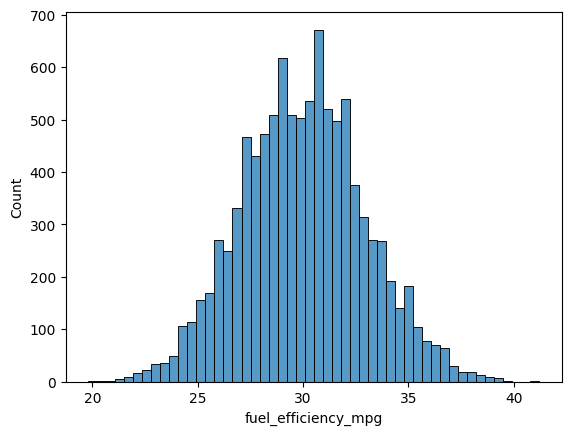

In [156]:
sns.histplot(df["fuel_efficiency_mpg"], bins=50)

In [157]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [158]:
median_hp = df["horsepower"].median()
print("Median horsepower:", median_hp)

Median horsepower: 254.0


SPLITING DATASET

In [159]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42) # set the random seed for reproducibility
idx = np.arange(n) # create an array of indices from 0 to n-1
np.random.shuffle(idx) ## shuffle the indices so that we can split the data randomly without focusing on one side of the data

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

CONFIRMING THE SPLIT

In [160]:
print(len(df_train))
print(len(df_val))
print(len(df_test))
print(len(df_train) + len(df_val) + len(df_test))

6000
2000
2000
10000


QUESTION 3

In [161]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [162]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].copy()
df_val = df.iloc[n_train:n_train + n_val].copy()
df_test = df.iloc[n_train + n_val:].copy()

In [163]:
horsepower_mean = df_train["horsepower"].mean()
print("Training mean horsepower:", horsepower_mean)
acceleration_mean = df_train["acceleration"].mean()
print("Training mean acceleration:", acceleration_mean)

Training mean horsepower: 254.46338337605272
Training mean acceleration: 18.890468856947294


MODEL WITH MISSING VALUE OF HOURSEPOWER COLUMN SET AS ZERO AND ACCELERATION WITH ITS MEAN

In [164]:
df_train_0 = df_train.copy() ### COPY SO THAT WE DON'T MODIFY THE ORIGINAL DATAFRAMES
df_val_0 = df_val.copy()

df_train_0["horsepower"] = df_train_0["horsepower"].fillna(0)
df_val_0["horsepower"] = df_val_0["horsepower"].fillna(0)

df_train_0["acceleration"] = df_train_0["acceleration"].fillna(acceleration_mean)
df_val_0["acceleration"] = df_val_0["acceleration"].fillna(acceleration_mean)

MODEL WITH MISSING VALUE OF HOURSEPOWER COLUMN SET WITH ITS MEAN AND ACCELERATION WITH ITS MEAN

In [165]:
df_train_mean = df_train.copy()
df_val_mean = df_val.copy()

df_train_mean["horsepower"] = df_train_mean["horsepower"].fillna(horsepower_mean)
df_val_mean["horsepower"] = df_val_mean["horsepower"].fillna(horsepower_mean)

df_train_mean["acceleration"] = df_train_mean["acceleration"].fillna(acceleration_mean)
df_val_mean["acceleration"] = df_val_mean["acceleration"].fillna(acceleration_mean)

In [166]:
selected_features = ["engine_displacement", "horsepower", "vehicle_weight", "model_year"]
target = "fuel_efficiency_mpg"

def prepare_features(train_data, val_data):
    X_train = train_data[selected_features].fillna(0)
    X_val = val_data[selected_features].fillna(0)
    return X_train.to_numpy(dtype=float), X_val.to_numpy(dtype=float)

X_train_0, X_val_0 = prepare_features(df_train_0, df_val_0)
X_train_mean, X_val_mean = prepare_features(df_train_mean, df_val_mean)

y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()

In [167]:
selected_features = ["engine_displacement", "horsepower", "vehicle_weight", "model_year"]
target = "fuel_efficiency_mpg"

def prepare_features(train_data, val_data):
    X_train = train_data[selected_features].fillna(0)
    X_val = val_data[selected_features].fillna(0)
    return X_train.to_numpy(dtype=float), X_val.to_numpy(dtype=float)

X_train_0, X_val_0 = prepare_features(df_train_0, df_val_0)
X_train_mean, X_val_mean = prepare_features(df_train_mean, df_val_mean)

y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()

TRAINING THE MODEL 

In [168]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.pinv(XTX)

    w = XTX_inv.dot(X.T).dot(y)

    return w[0], w[1:]



w0_0, w_0 = train_linear_regression(X_train_0, y_train)

w0_mean, w_mean = train_linear_regression(X_train_mean, y_train)

Predict and calculate RMSE

In [169]:
def predict(X, w0, w):
    return w0 + X.dot(w)


def rmse(y, y_pred):
    error = y - y_pred
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [170]:
# Option A: missing horsepower filled with 0
y_pred_0 = predict(X_val_0, w0_0, w_0)
score_0 = rmse(y_val, y_pred_0)

# Option B: missing horsepower filled with training mean
y_pred_mean = predict(X_val_mean, w0_mean, w_mean)
score_mean = rmse(y_val, y_pred_mean)

print("RMSE with 0:", round(score_0, 3))
print("RMSE with mean:", round(score_mean, 3))

RMSE with 0: 2.182
RMSE with mean: 2.179


In [171]:
if score_0 < score_mean:
    print("Filling missing values with 0 gives better RMSE.")
elif score_mean < score_0:
    print("Filling missing values with the mean gives better RMSE.")
else:
    print("Both options give the same RMSE, WHICH ARE QUALLY GOOD.")

Filling missing values with the mean gives better RMSE.


QUESTION 4: REGULAZING THE MODEL

In [172]:
# Fill all missing values with 0
df_train_0 = df_train.fillna(0).copy()
df_val_0 = df_val.fillna(0).copy()

PREPARE THE FEATURE

In [173]:
selected_features = ["engine_displacement", "horsepower", "vehicle_weight", "model_year"]
target = "fuel_efficiency_mpg"

X_train_df = df_train_0[selected_features].fillna(0)
X_val_df = df_val_0[selected_features].fillna(0)

y_train = df_train_0[target].to_numpy()
y_val = df_val_0[target].to_numpy()

X_train = X_train_df.to_numpy(dtype=float)
X_val = X_val_df.to_numpy(dtype=float)

LET ADD THE REGULRIZED LINER REGRESSION FUNCTION

In [174]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)

    # Add regularization
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.pinv(XTX)
    w = XTX_inv.dot(X.T).dot(y)

    return w[0], w[1:]

PREDICTION AND RMSE FUCNTION

In [175]:
def predict(X, w0, w):
    return w0 + X.dot(w)


def rmse(y, y_pred):
    error = y - y_pred
    mse = (error ** 2).mean()
    return np.sqrt(mse)

TEST EVERY VALUE OF r

In [176]:
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

scores = {}

for r in r_values:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    y_pred = predict(X_val, w0, w)

    score = rmse(y_val, y_pred)

    scores[r] = round(score, 4)

    print(f"r = {r:<6} RMSE = {scores[r]}")

r = 0      RMSE = 2.1815
r = 0.01   RMSE = 2.1818
r = 0.1    RMSE = 2.1985
r = 1      RMSE = 2.3226
r = 5      RMSE = 2.3831
r = 10     RMSE = 2.3932
r = 100    RMSE = 2.403


FIND THE BEST VALUE OF r

In [177]:
best_score = min(scores.values())

best_r = min(
    r for r, score in scores.items()
    if score == best_score
)

print("Best r:", best_r)
print("Best RMSE:", best_score)

Best r: 0
Best RMSE: 2.1815


QUESTION 5

In [180]:
np.random.seed(3)
idx = np.arange(10)
np.random.shuffle(idx)
print(idx)

[5 4 1 2 9 6 7 0 3 8]


In [181]:
selected_features = ["engine_displacement", "horsepower", "vehicle_weight", "model_year"]
target = "fuel_efficiency_mpg"
seeds = list(range(10))
scores = []

for seed in seeds:
    # 1. Calculate the split sizes
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    # 2. Shuffle the row positions using this seed
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    # 3. Split into training, validation, and test sets
    df_train_raw = df.iloc[idx[:n_train]].copy()
    df_val_raw = df.iloc[n_train:n_train + n_val].copy()
    df_test_raw = df.iloc[n_train + n_val:].copy()

    # 4. Extract target before feature selection
    y_train = df_train_raw[target].to_numpy()
    y_val = df_val_raw[target].to_numpy()

    # 5. Keep only the four allowed predictors and fill missing values with 0
    X_train = df_train_raw[selected_features].fillna(0).to_numpy(dtype=float)
    X_val = df_val_raw[selected_features].fillna(0).to_numpy(dtype=float)

    # 6. Train ordinary linear regression (r = 0)
    w0, w = train_linear_regression(X_train, y_train)

    # 7. Predict and evaluate on validation data
    y_pred = predict(X_val, w0, w)
    score = rmse(y_val, y_pred)

    scores.append(score)

    print(f"seed={seed}, RMSE={score:.4f}")

seed=0, RMSE=2.1815
seed=1, RMSE=2.1781
seed=2, RMSE=2.1796
seed=3, RMSE=2.1817
seed=4, RMSE=2.1796
seed=5, RMSE=2.1815
seed=6, RMSE=2.1812
seed=7, RMSE=2.1783
seed=8, RMSE=2.1794
seed=9, RMSE=2.1817


CALCULATING THE STD

In [182]:
std = np.std(scores)

print("Standard deviation:", round(std, 3))

Standard deviation: 0.001


In [183]:
print("Exact standard deviation:", np.std(scores))
print("Rounded standard deviation:", round(np.std(scores), 3))

Exact standard deviation: 0.0013503038829447134
Rounded standard deviation: 0.001


QUESTION 6.

In [184]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.pinv(XTX)
    w = XTX_inv.dot(X.T).dot(y)

    return w[0], w[1:]

In [185]:
selected_features = ["engine_displacement", "horsepower", "vehicle_weight", "model_year"]

# 1. Split the dataset using seed 9
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].copy()
df_val = df.iloc[n_train:n_train + n_val].copy()
df_test = df.iloc[n_train + n_val:].copy()

# 2. Combine training and validation datasets
df_train_full = pd.concat([df_train, df_val], ignore_index=True)

# 3. Fill missing values with 0
X_train_full_df = df_train_full[selected_features].fillna(0)
X_test_df = df_test[selected_features].fillna(0)

# 4. Separate features and target
target = "fuel_efficiency_mpg"
y_train_full = df_train_full[target].to_numpy()
y_test = df_test[target].to_numpy()

X_train_full = X_train_full_df.to_numpy(dtype=float)
X_test = X_test_df.to_numpy(dtype=float)

# 5. Train with regularization r = 0.001
w0, w = train_linear_regression_reg(
    X_train_full, y_train_full, r=0.001
)

# 6. Evaluate on the test dataset
y_pred = predict(X_test, w0, w)
test_rmse = rmse(y_test, y_pred)

print("Test RMSE:", round(test_rmse, 3))

Test RMSE: 2.278
